# Stroke Prediction: Task 2 (Gather, Prepare and Refine the Dataset)

## 1. Import libraries and load the dataset

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

# Upload healthcare-dataset-stroke-data.csv when prompted
from google.colab import files
uploaded = files.upload()

df = pd.read_csv('healthcare-dataset-stroke-data.csv')
df.head()

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 2. Inspect the raw data (BEFORE)

In [7]:
print('Shape:', df.shape)
df.info()

Shape: (5110, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [8]:
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
print('\nClass balance (stroke):')
print(df['stroke'].value_counts())
print((df['stroke'].value_counts(normalize=True) * 100).round(2))

Missing values per column:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Duplicate rows: 0

Class balance (stroke):
stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


In [9]:
for col in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    print(df[col].value_counts(), '\n')
df.describe()

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64 

ever_married
Yes    3353
No     1757
Name: count, dtype: int64 

work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64 

Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64 

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64 



,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


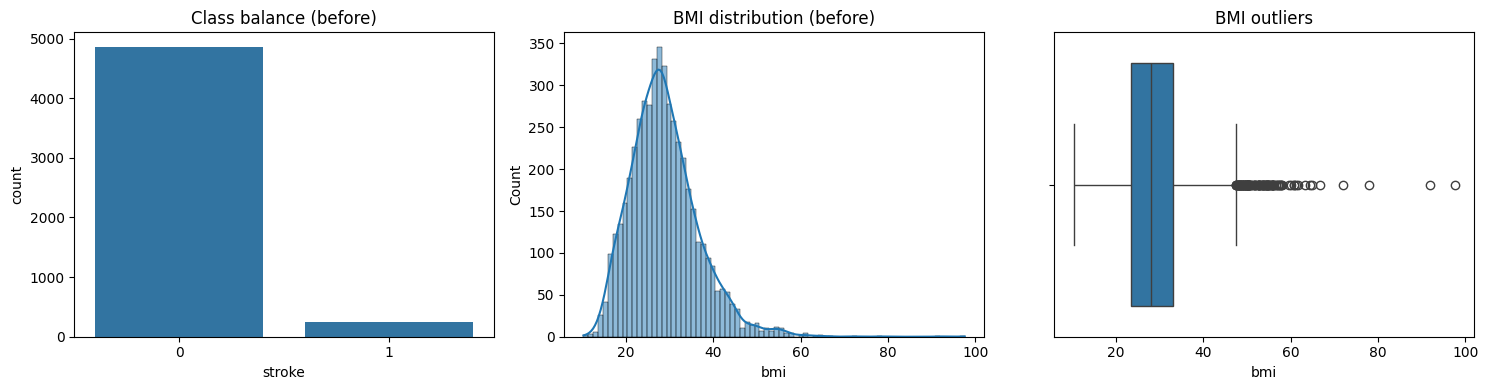

In [10]:
# Charts for BEFORE evidence
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(x='stroke', data=df, ax=ax[0]); ax[0].set_title('Class balance (before)')
sns.histplot(df['bmi'].dropna(), kde=True, ax=ax[1]); ax[1].set_title('BMI distribution (before)')
sns.boxplot(x=df['bmi'], ax=ax[2]); ax[2].set_title('BMI outliers')
plt.tight_layout(); plt.show()

## 3. Data cleaning

In [11]:
before_rows = len(df)
df_clean = df.copy()

# 3a. Drop 'id' (just an identifier, no predictive value)
df_clean = df_clean.drop(columns=['id'])

# 3b. Remove the single 'Other' gender row (too rare to learn from)
df_clean = df_clean[df_clean['gender'] != 'Other']

# 3c. Remove duplicates (none expected, but checked)
df_clean = df_clean.drop_duplicates()

print('Rows before:', before_rows, '| Rows after:', len(df_clean))

Rows before: 5110 | Rows after: 5109


**Handling missing values:** `bmi` has 201 missing values. They are filled with the **median** (after splitting, so test data does not influence it, see section 5). The median is used because BMI is right-skewed with outliers (max about 97.6). Rows are not dropped because that would delete about 40 stroke cases from an already small group.

**`smoking_status = Unknown`** (about 30% of rows) is kept as its own category, because it may be informative and dropping it would remove too much data.

## 4. Encode categorical values

In [12]:
df_enc = df_clean.copy()

# Binary columns -> 0/1
df_enc['gender'] = df_enc['gender'].map({'Male': 1, 'Female': 0})
df_enc['ever_married'] = df_enc['ever_married'].map({'Yes': 1, 'No': 0})
df_enc['Residence_type'] = df_enc['Residence_type'].map({'Urban': 1, 'Rural': 0})

# Multi-category columns -> one-hot encoding
df_enc = pd.get_dummies(df_enc, columns=['work_type', 'smoking_status'], drop_first=True, dtype=int)

df_enc.head()

,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,1,67.0,0,1,1,1,228.69,36.6,1,0,1,0,0,1,0,0
1,0,61.0,0,0,1,0,202.21,NaN,1,0,0,1,0,0,1,0
2,1,80.0,0,1,1,0,105.92,32.5,1,0,1,0,0,0,1,0
3,0,49.0,0,0,1,1,171.23,34.4,1,0,1,0,0,0,0,1
4,0,79.0,1,0,1,0,174.12,24.0,1,0,0,1,0,0,1,0


## 5. Split training and testing data

In [13]:
X = df_enc.drop('stroke', axis=1)
y = df_enc['stroke']

# stratify keeps the same stroke ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Stroke % in train:', round(y_train.mean() * 100, 2))
print('Stroke % in test :', round(y_test.mean() * 100, 2))

Train: (4087, 15) | Test: (1022, 15)
Stroke % in train: 4.87
Stroke % in test : 4.89


## 6. Review and refine: missing values

In [14]:
print('BMI missing BEFORE  -> train:', X_train['bmi'].isnull().sum(), '| test:', X_test['bmi'].isnull().sum())

bmi_median = X_train['bmi'].median()   # from training data only
X_train = X_train.copy(); X_test = X_test.copy()
X_train['bmi'] = X_train['bmi'].fillna(bmi_median)
X_test['bmi'] = X_test['bmi'].fillna(bmi_median)

print('BMI median used:', round(bmi_median, 2))
print('BMI missing AFTER   -> train:', X_train['bmi'].isnull().sum(), '| test:', X_test['bmi'].isnull().sum())

BMI missing BEFORE  -> train: 163 | test: 38
BMI median used: 28.1
BMI missing AFTER   -> train: 0 | test: 0


## 7. Feature scaling

In [15]:
num_cols = ['age', 'avg_glucose_level', 'bmi']

scaler = StandardScaler()
X_train_scaled = X_train.copy(); X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit on train only
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print('BEFORE scaling (train):'); print(X_train[num_cols].describe().loc[['mean', 'std']].round(2))
print('\nAFTER scaling (train):'); print(X_train_scaled[num_cols].describe().loc[['mean', 'std']].round(2))

BEFORE scaling (train):
        age  avg_glucose_level    bmi
mean  43.26             105.90  28.85
std   22.64              44.68   7.74

AFTER scaling (train):
      age  avg_glucose_level  bmi
mean -0.0                0.0 -0.0
std   1.0                1.0  1.0


## 8. Review and refine: class imbalance

In [16]:
print('Class balance BEFORE (train):'); print(y_train.value_counts())

# Oversample the minority class (stroke = 1) in the TRAINING set only
train_df = X_train_scaled.copy(); train_df['stroke'] = y_train
majority = train_df[train_df['stroke'] == 0]
minority = train_df[train_df['stroke'] == 1]
minority_up = resample(minority, replace=True, n_samples=len(majority), random_state=42)
train_bal = pd.concat([majority, minority_up]).sample(frac=1, random_state=42)

X_train_bal = train_bal.drop('stroke', axis=1)
y_train_bal = train_bal['stroke']

print('\nClass balance AFTER (train):'); print(y_train_bal.value_counts())

Class balance BEFORE (train):
stroke
0    3888
1     199
Name: count, dtype: int64

Class balance AFTER (train):
stroke
0    3888
1    3888
Name: count, dtype: int64


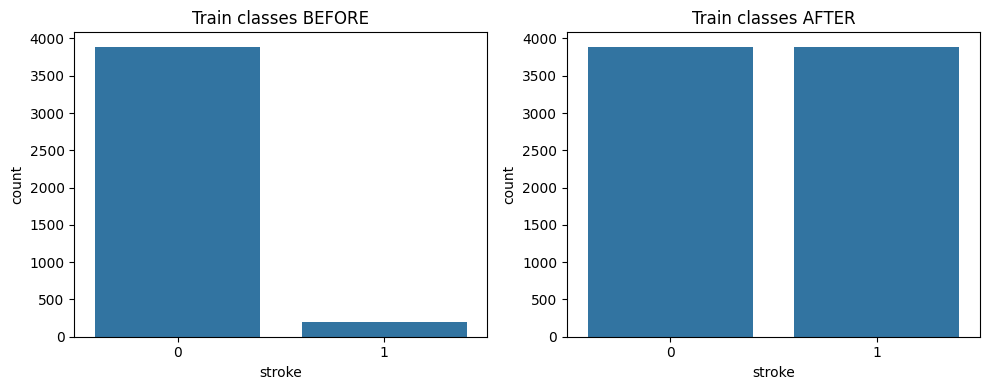

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x=y_train, ax=ax[0]); ax[0].set_title('Train classes BEFORE')
sns.countplot(x=y_train_bal, ax=ax[1]); ax[1].set_title('Train classes AFTER')
plt.tight_layout(); plt.show()

**Why only the training set?** The test set is left untouched so model evaluation reflects real-world data (about 5% stroke cases). Oversampling the test set would give misleadingly good results.

**Note:** for stronger marks you can use SMOTE instead of simple oversampling: `!pip install imbalanced-learn`, then `from imblearn.over_sampling import SMOTE` and `SMOTE(random_state=42).fit_resample(X_train_scaled, y_train)`.

## 9. Final summary (before vs after)

In [18]:
summary = pd.DataFrame({
    'Check': ['Rows', 'Columns', 'Missing BMI', 'Categorical columns', 'Stroke % (train)'],
    'Before': [len(df), df.shape[1], int(df['bmi'].isnull().sum()), 5, round(df['stroke'].mean() * 100, 2)],
    'After': [len(X_train_bal), X_train_bal.shape[1], int(X_train_bal['bmi'].isnull().sum()), 0, round(y_train_bal.mean() * 100, 2)]
})
summary

,Check,Before,After
0,Rows,5110.00,7776.0
1,Columns,12.00,15.0
2,Missing BMI,201.00,0.0
3,Categorical columns,5.00,0.0
4,Stroke % (train),4.87,50.0


---
# TASK 3: Develop an AI Solution (Logistic Regression)

## 10. Imports and evaluation helper

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve)

results = {}   # stores every model's test scores for the final comparison

def evaluate(name, probs, y_true, threshold=0.5):
    preds = (probs >= threshold).astype(int)
    results[name] = {
        'Accuracy': accuracy_score(y_true, preds),
        'Precision': precision_score(y_true, preds, zero_division=0),
        'Recall': recall_score(y_true, preds),
        'F1': f1_score(y_true, preds),
        'ROC-AUC': roc_auc_score(y_true, probs)}
    print(f'--- {name} (threshold = {threshold}) ---')
    print(classification_report(y_true, preds, target_names=['No stroke', 'Stroke'], zero_division=0))
    ConfusionMatrixDisplay(confusion_matrix(y_true, preds), display_labels=['No stroke', 'Stroke']).plot(cmap='Blues')
    plt.title(name); plt.show()

## 11. P5: Train the initial Logistic Regression model

The initial model uses the prepared data from Task 2 (cleaned, encoded, split and scaled) **without** any imbalance handling. This is the baseline to improve on.

--- 1. Baseline Logistic Regression (threshold = 0.5) ---
              precision    recall  f1-score   support

   No stroke       0.95      1.00      0.98       972
      Stroke       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



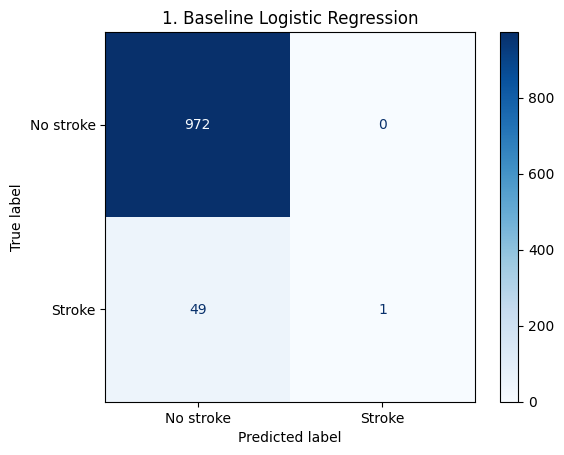

In [20]:
model_base = LogisticRegression(max_iter=1000, random_state=42)
model_base.fit(X_train_scaled, y_train)

probs_base = model_base.predict_proba(X_test_scaled)[:, 1]
evaluate('1. Baseline Logistic Regression', probs_base, y_test)

**Observation:** the baseline looks accurate (about 95%) but this is misleading. Only about 5% of patients have a stroke, so a model that predicts "no stroke" for almost everyone scores high accuracy. Recall for stroke is only about 2%, so it misses nearly all real stroke cases, which is unacceptable for a healthcare tool. This is why the model must be refined.

## 12. M3: Test and refine the model

### Refinement 1: Handle class imbalance (oversampled training data)

--- 2. Logistic Regression + oversampling (threshold = 0.5) ---
              precision    recall  f1-score   support

   No stroke       0.99      0.73      0.84       972
      Stroke       0.13      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.81      1022



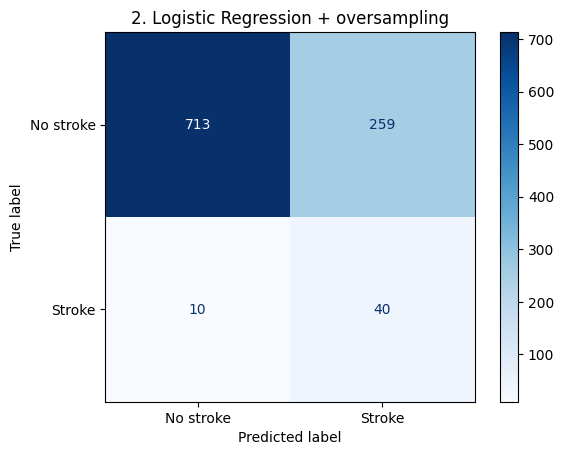

In [21]:
model_over = LogisticRegression(max_iter=1000, random_state=42)
model_over.fit(X_train_bal, y_train_bal)    # balanced training set from section 8

probs_over = model_over.predict_proba(X_test_scaled)[:, 1]
evaluate('2. Logistic Regression + oversampling', probs_over, y_test)

Refinement 2: Hyperparameter

Instead of duplicating rows, `class_weight='balanced'` makes the model penalise missed strokes more heavily. `GridSearchCV` then searches for the best regularisation strength `C` and penalty type using 5-fold stratified cross-validation, scored on F1 (a balance of precision and recall).

Best parameters: {'C': 100, 'penalty': 'l1'}
Best cross-validated F1: 0.2379
--- 3. Tuned + class weights (threshold = 0.5) ---
              precision    recall  f1-score   support

   No stroke       0.99      0.74      0.84       972
      Stroke       0.13      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.81      1022



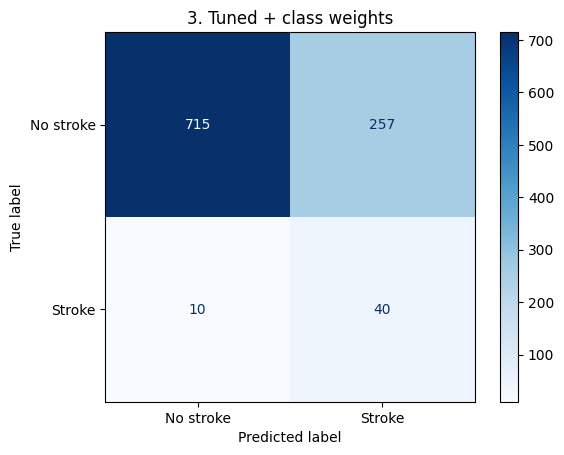

In [22]:
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100], 'penalty': ['l1', 'l2']}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    LogisticRegression(solver='liblinear', class_weight='balanced', max_iter=1000, random_state=42),
    param_grid, scoring='f1', cv=cv)
grid.fit(X_train_scaled, y_train)

print('Best parameters:', grid.best_params_)
print('Best cross-validated F1:', round(grid.best_score_, 4))

model_tuned = grid.best_estimator_
probs_tuned = model_tuned.predict_proba(X_test_scaled)[:, 1]
evaluate('3. Tuned + class weights', probs_tuned, y_test)

Refinement 3: Decision threshold

By default a patient is flagged when the probability is 0.5 or more. The best threshold is chosen using **cross-validated predictions on the training data only**, so the test set stays unseen.

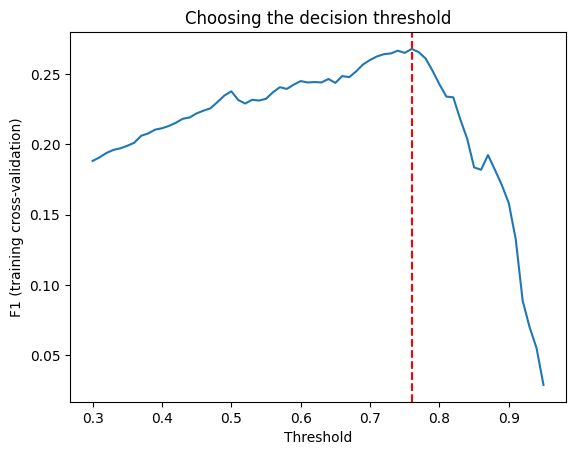

Best threshold: 0.76
--- 4. Tuned + threshold (FINAL) (threshold = 0.7600000000000005) ---
              precision    recall  f1-score   support

   No stroke       0.98      0.89      0.93       972
      Stroke       0.23      0.64      0.34        50

    accuracy                           0.88      1022
   macro avg       0.60      0.76      0.63      1022
weighted avg       0.94      0.88      0.90      1022



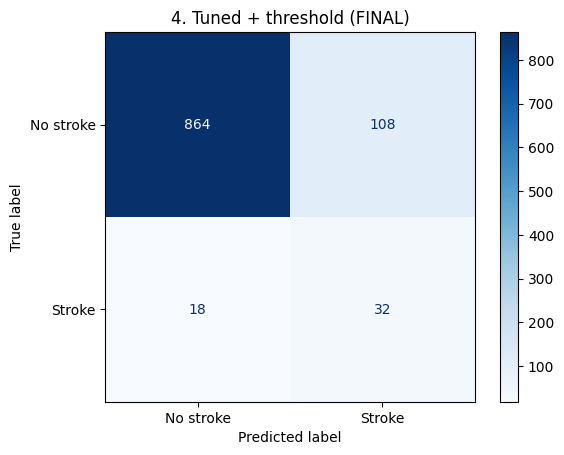

In [23]:
cv_probs = cross_val_predict(model_tuned, X_train_scaled, y_train, cv=cv, method='predict_proba')[:, 1]

thresholds = np.arange(0.30, 0.96, 0.01)
f1_scores = [f1_score(y_train, (cv_probs >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[int(np.argmax(f1_scores))]

plt.plot(thresholds, f1_scores); plt.axvline(best_threshold, color='red', linestyle='--')
plt.xlabel('Threshold'); plt.ylabel('F1 (training cross-validation)'); plt.title('Choosing the decision threshold')
plt.show()
print('Best threshold:', round(best_threshold, 2))

evaluate('4. Tuned + threshold (FINAL)', probs_tuned, y_test, threshold=best_threshold)

### Comparison of all models

In [24]:
comparison = pd.DataFrame(results).T.round(3)
comparison

,Accuracy,Precision,Recall,F1,ROC-AUC
1. Baseline Logistic Regression,0.952,1.000,0.02,0.039,0.839
2. Logistic Regression + oversampling,0.737,0.134,0.80,0.229,0.838
3. Tuned + class weights,0.739,0.135,0.80,0.231,0.840
4. Tuned + threshold (FINAL),0.877,0.229,0.64,0.337,0.840


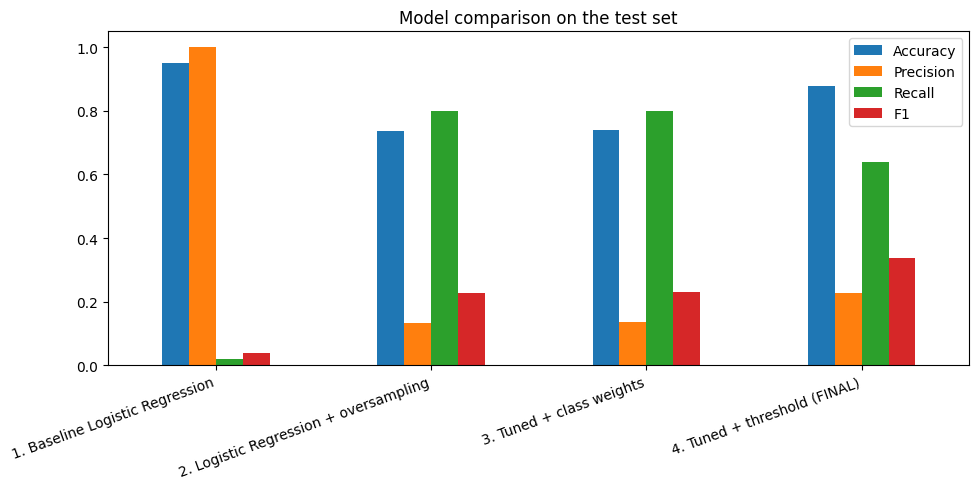

In [25]:
comparison[['Accuracy', 'Precision', 'Recall', 'F1']].plot(kind='bar', figsize=(10, 5))
plt.title('Model comparison on the test set'); plt.xticks(rotation=20, ha='right')
plt.ylim(0, 1.05); plt.legend(loc='upper right'); plt.tight_layout(); plt.show()

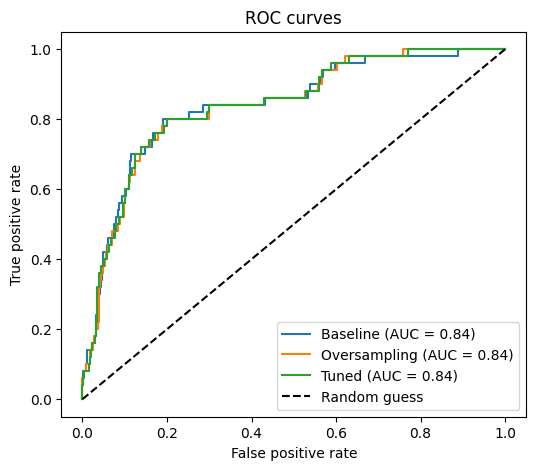

In [26]:
plt.figure(figsize=(6, 5))
for name, probs in [('Baseline', probs_base), ('Oversampling', probs_over), ('Tuned', probs_tuned)]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, probs):.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.title('ROC curves')
plt.legend(); plt.show()

## 13. D2: Evaluate the effectiveness of the AI solution

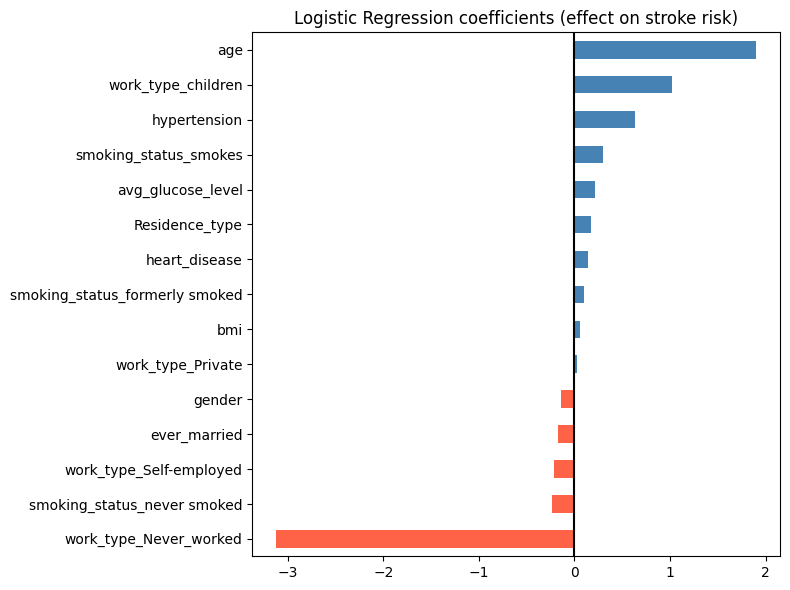

In [27]:
coefs = pd.Series(model_tuned.coef_[0], index=X_train_scaled.columns).sort_values()
coefs.plot(kind='barh', figsize=(8, 6), color=['tomato' if v < 0 else 'steelblue' for v in coefs])
plt.title('Logistic Regression coefficients (effect on stroke risk)'); plt.axvline(0, color='black')
plt.tight_layout(); plt.show()

### Evaluation

**Performance .** As we talked about this earlier this initial baseline bring about 95% accuracy but what was wrong is it only detects 1 out the 50 in the test which was very misleading so it failed our main objective of finding stroke patients but after the refinemetns we did like handling class imbalances and aslo the hyperparameter changes which made the accuracy drop to 88% but its okay cause thats better than a flase alarm.

**Strengths.** Logistic Regression is simple, fast and interpretable. this thing trains in second and the doctors who work there could be told easily.

**Weaknesses.** Its Precision is low because 3 out of the 4 patients who it flagged didnt even have stroke. the model is linear and its job cant be hard.

**Model choice.** Logistic Regression was chosen because it is required by the assignment and its easily interpretable which matters alot.

**Future improvements.** collect more stroke cases and needed features and before its used it should be checked with a professional and lastly the model shouldnt replace jobs it should work with the people.